# Length of stay: what drives the predictions, and why scores are low

Two questions:
1. **Which intake features do the tuned models rely on, and in which direction?**
2. **Why do even the best models reach only about 0.40 macro-F1 and 0.34 QWK?** Is the problem the models, the amount of data, or the information available at intake?

We use the tuned **random forest** (best macro-F1/QWK) and the tuned **gradient boosting** model from notebooks 04 and 06, with the same split (train < 2022, val = 2022; test still untouched).

All results here are **associations**. A feature the model relies on is predictive, not necessarily causal.

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor)
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

sys.path.append(str(Path.cwd().parent))
import utils

RESULTS_DIR = Path("results")
L = utils.LOS_BIN_LABELS
train, val, test = utils.load_los_splits()

def tuned(est, name):
    return utils.with_params(est, json.loads((RESULTS_DIR / f"{name}_tuned.json").read_text())["best_params"])

RF = tuned(RandomForestClassifier(n_jobs=-1, random_state=utils.SEED), "random_forest")
GB = tuned(HistGradientBoostingClassifier(random_state=utils.SEED), "gradient_boosting")

def fit(est, tr, feats=utils.FEATURES, cat=None, target="los_bin"):
    pre = utils.make_preprocessor(categorical=cat) if cat else utils.make_preprocessor()
    return Pipeline([("pre", pre), ("model", utils.with_params(est, {}))]).fit(tr[feats], tr[target])

def scores(y, p):
    m = utils.classification_metrics(y, p, labels=L, verbose=False)
    return {"accuracy": m["accuracy"], "macro_f1": m["macro_f1"],
            "qwk": utils.quadratic_weighted_kappa(y, p, labels=L)}

t0 = time.time()
rf_pipe, gb_pipe = fit(RF, train), fit(GB, train)
print(f"fitted in {time.time() - t0:.0f}s")
pd.DataFrame({"Random forest (tuned)": scores(val.los_bin, rf_pipe.predict(val[utils.FEATURES])),
              "Gradient boosting (tuned)": scores(val.los_bin, gb_pipe.predict(val[utils.FEATURES]))}).T.round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split


fitted in 53s


,accuracy,macro_f1,qwk
Random forest (tuned),0.483,0.405,0.342
Gradient boosting (tuned),0.517,0.383,0.314


## 1. Feature importance (grouped permutation importance)

For each group of related intake features, all of its columns are **shuffled together** across the val rows, and we measure how much val macro-F1 drops (5 repeats).
- **A big drop** means the model depends on that information.
- **About zero** means the model can do without it.

**Why grouped:** age appears three ways (`age_days`, `log_age_days`, `age_group`). Shuffled one at a time, the other two copies cover for it and age looks unimportant. Groups are defined in `utils.FEATURE_GROUPS`.

In [2]:
imp = {}
for name, pipe in [("Random forest", rf_pipe), ("Gradient boosting", gb_pipe)]:
    t0 = time.time()
    imp[name] = utils.grouped_permutation_importance(pipe, val[utils.FEATURES], val["los_bin"], n_repeats=5)
    print(f"{name}: baseline val macro-F1 {imp[name].attrs['baseline_score']:.3f} ({time.time() - t0:.0f}s)")

both = pd.concat({k: v.set_index("group")[["importance", "std"]] for k, v in imp.items()}, axis=1)
both = both.sort_values(("Random forest", "importance"), ascending=False)
both.round(4)

Random forest: baseline val macro-F1 0.405 (9s)


Gradient boosting: baseline val macro-F1 0.383 (10s)


Random forest         Gradient boosting        
                       importance     std        importance     std
group                                                              
age                        0.0990  0.0018            0.0781  0.0054
breed                      0.0344  0.0030            0.0352  0.0043
species                    0.0242  0.0026            0.0231  0.0016
owner-given name           0.0210  0.0021            0.0228  0.0024
intake type                0.0147  0.0021            0.0151  0.0044
sex & sterilization        0.0122  0.0024            0.0128  0.0014
intake condition           0.0078  0.0009            0.0077  0.0011
intake date & time         0.0037  0.0055            0.0117  0.0030
found location             0.0032  0.0016            0.0029  0.0021
shelter history            0.0015  0.0006            0.0008  0.0008
color                      0.0010  0.0017            0.0052  0.0036

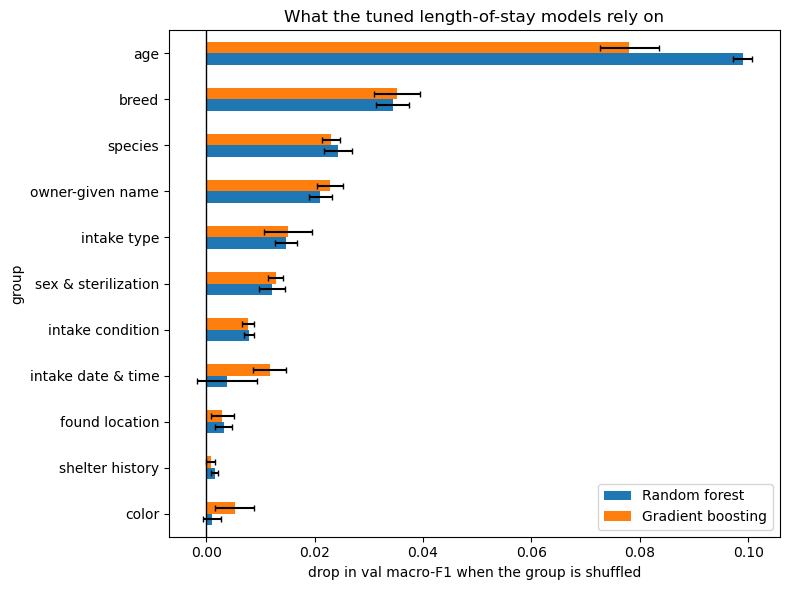

In [3]:
plot = pd.DataFrame({k: both[(k, "importance")] for k in imp}).iloc[::-1]
err = pd.DataFrame({k: both[(k, "std")] for k in imp}).iloc[::-1]
ax = plot.plot(kind="barh", xerr=err, figsize=(8, 6), capsize=2)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("drop in val macro-F1 when the group is shuffled")
ax.set_title("What the tuned length-of-stay models rely on")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_importance_grouped.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Direction of the effects (descriptive, training years)

Importance says *how much* a feature matters, not *which way*. The tables below show the raw relationship in the training data for the most important groups. Two summaries per group:
- **median stay** in days;
- **long-stay share**: the share of stays of 30+ days, the two longest bins combined.

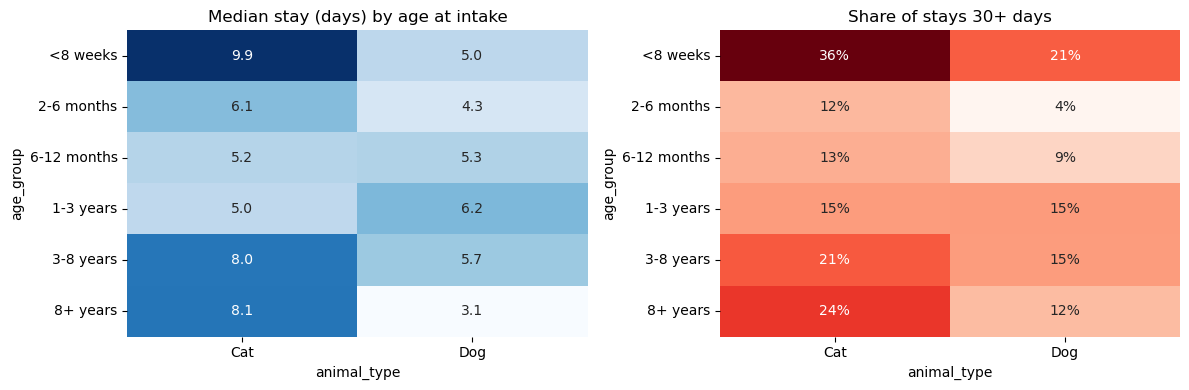

In [4]:
tr = train.assign(long_stay=train["los_days"] >= 30)

def summarize(col, data=tr, min_n=200):
    g = data.groupby(col, observed=True).agg(n=("los_days", "size"),
                                             median_days=("los_days", "median"),
                                             long_stay_share=("long_stay", "mean"))
    return g[g["n"] >= min_n].round(3)

age_order = ["<8 weeks", "2-6 months", "6-12 months", "1-3 years", "3-8 years", "8+ years"]
pivot = tr.pivot_table(index="age_group", columns="animal_type", values="long_stay", aggfunc="mean").reindex(age_order)
med = tr.pivot_table(index="age_group", columns="animal_type", values="los_days", aggfunc="median").reindex(age_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(med, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Median stay (days) by age at intake")
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", ax=axes[1], cbar=False)
axes[1].set_title("Share of stays 30+ days")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "los_by_age_species.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
for col in ["intake_type", "intake_condition", "fixed_status", "has_name", "is_return"]:
    display(summarize(col).sort_values("median_days", ascending=False).rename_axis(col))

,n,median_days,long_stay_share
intake_type,,,
Public Assist,7630,8.738,0.100
Abandoned,623,8.131,0.236
Owner Surrender,26647,7.260,0.215
Stray,91615,5.110,0.175
Euthanasia Request,242,0.113,0.045


,n,median_days,long_stay_share
intake_condition,,,
Normal,110977,5.947,0.173
Other,228,5.842,0.246
Injured,6407,5.217,0.215
Nursing,3773,3.047,0.310
Sick,4258,3.047,0.158
Aged,450,2.125,0.102
Neonatal,230,0.743,0.274


,n,median_days,long_stay_share
fixed_status,,,
Intact,84843,6.162,0.203
Fixed,37405,5.083,0.145
Unknown,4510,0.151,0.006


,n,median_days,long_stay_share
has_name,,,
0,64416,6.124,0.219
1,62342,5.124,0.138


,n,median_days,long_stay_share
is_return,,,
0,112640,5.832,0.182
1,14118,5.223,0.157


## 3. Why are the scores low?

Six checks, each testing a different explanation:

| If the problem were… | …then we would expect | Check |
|---|---|---|
| too little data | val score keeps rising as training data grows | 3a learning curve |
| the model choice | a flexible model explains much of the variation in stay length | 3b variance explained |
| a weak model | the tuned model barely beats a simple lookup table | 3c profile lookup table |
| missing information | adding information from *after* intake helps a lot | 3d oracle |
| noisy labels | many stays sit right next to a bin edge | 3e bin-edge noise |
| identical-looking animals with different stays | wide spread of stays within one intake profile | 3f same-profile spread |

### 3a. Learning curve: would more data help?

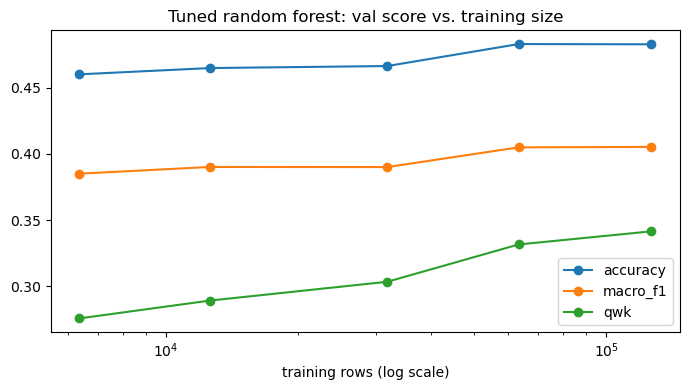

,train_fraction,train_rows,accuracy,macro_f1,qwk
0,0.05,6357,0.460,0.385,0.276
1,0.10,12597,0.465,0.390,0.289
2,0.25,31827,0.466,0.390,0.304
3,0.50,63316,0.483,0.405,0.332
4,1.00,126758,0.483,0.405,0.342


In [6]:
rows = []
rng = np.random.default_rng(utils.SEED)
animals = train["animal_id"].unique()
for frac in [0.05, 0.1, 0.25, 0.5, 1.0]:
    keep = set(rng.choice(animals, int(len(animals) * frac), replace=False)) if frac < 1 else set(animals)
    sub = train[train["animal_id"].isin(keep)]
    p = fit(RF, sub)
    rows.append({"train_fraction": frac, "train_rows": len(sub),
                 **scores(val.los_bin, p.predict(val[utils.FEATURES]))})
lc = pd.DataFrame(rows)
ax = lc.plot(x="train_rows", y=["accuracy", "macro_f1", "qwk"], marker="o", logx=True, figsize=(7, 4))
ax.set_title("Tuned random forest: val score vs. training size"); ax.set_xlabel("training rows (log scale)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "learning_curve.png", dpi=150, bbox_inches="tight"); plt.show()
lc.round(3)

### 3b. How much of the variation in stay length do intake features explain?

Skip the bins and predict log(1 + days) directly with gradient boosting. R² is the share of variance explained.

In [7]:
y_tr, y_va = np.log1p(train["los_days"]), np.log1p(val["los_days"])
reg = Pipeline([("pre", utils.make_preprocessor()),
                ("model", HistGradientBoostingRegressor(random_state=utils.SEED))]).fit(train[utils.FEATURES], y_tr)
pred_va = reg.predict(val[utils.FEATURES])
r2 = pd.Series({"R² train (log days)": r2_score(y_tr, reg.predict(train[utils.FEATURES])),
                "R² val (log days)": r2_score(y_va, pred_va),
                "median absolute error val (days)": float(np.median(np.abs(np.expm1(pred_va) - val["los_days"])))})
r2.round(3)

R² train (log days)                 0.297
R² val (log days)                   0.222
median absolute error val (days)    6.194
dtype: float64

### 3c. Does the model beat a simple profile lookup table?

Describe each animal by five coarse intake facts: species, age group, intake type, intake condition and sterilization status. Predict the most common bin for that profile in the training data, falling back to the overall majority for unseen profiles.

In [8]:
keys = ["animal_type", "age_group", "intake_type", "intake_condition", "fixed_status"]
lookup = train.groupby(keys, observed=True)["los_bin"].agg(lambda s: s.value_counts().idxmax())
pred_lookup = val.join(lookup.rename("pred"), on=keys)["pred"].fillna(train["los_bin"].mode()[0])
print(f"{train.groupby(keys, observed=True).ngroups} profiles in train; "
      f"{val.join(lookup.rename('pred'), on=keys)['pred'].isna().mean():.1%} of val rows unseen")
cmp3c = pd.DataFrame({"majority baseline": scores(val.los_bin, np.full(len(val), "<1 week")),
                      "5-feature profile lookup": scores(val.los_bin, pred_lookup),
                      "tuned random forest (26 features)": scores(val.los_bin, rf_pipe.predict(val[utils.FEATURES]))}).T
cmp3c.round(3)

620 profiles in train; 0.7% of val rows unseen


,accuracy,macro_f1,qwk
majority baseline,0.432,0.151,0.000
5-feature profile lookup,0.453,0.285,0.145
tuned random forest (26 features),0.483,0.405,0.342


### 3d. Oracle: what if the model knew things that happen *after* intake?

**Diagnostic only, not a usable model.** We add the animal's eventual outcome (adopted, transferred, …) as a feature. If scores jumped to 0.8 or higher, intake data would be the bottleneck in a fixable way. If they rise only modestly, even large amounts of extra information leave stay length uncertain.

In [9]:
feats_o = utils.FEATURES + ["outcome_group"]
cat_o = utils.CATEGORICAL_FEATURES + ["outcome_group"]
oracle = fit(RF, train, feats=feats_o, cat=cat_o)
pd.DataFrame({"tuned random forest": scores(val.los_bin, rf_pipe.predict(val[utils.FEATURES])),
              "+ eventual outcome (oracle)": scores(val.los_bin, oracle.predict(val[feats_o]))}).T.round(3)

,accuracy,macro_f1,qwk
tuned random forest,0.483,0.405,0.342
+ eventual outcome (oracle),0.577,0.487,0.565


### 3e. Label noise at the bin edges

In [10]:
d = val["los_days"]
edge = {f"±{w} day(s) of 7/30/90": float(sum(((d > e - w) & (d < e + w)).sum() for e in [7, 30, 90]) / len(val))
        for w in [1, 2, 3]}
pd.Series(edge).map("{:.1%}".format)

±1 day(s) of 7/30/90    11.4%
±2 day(s) of 7/30/90    21.5%
±3 day(s) of 7/30/90    32.2%
dtype: object

### 3f. Same profile, different stays

The five most common intake profiles in val, and how their stays spread across the bins.

In [11]:
prof = val.groupby(keys, observed=True)
top = prof.size().nlargest(5).index
spread = (val.set_index(keys).loc[top].groupby(level=list(range(len(keys))), observed=True)["los_bin"]
          .value_counts(normalize=True).unstack()[L])
spread["n"] = prof.size().loc[top]
spread.round(2)

los_bin                                                           <1 week  \
animal_type age_group  intake_type intake_condition fixed_status            
Cat         2-6 months Stray       Normal           Intact           0.34   
            <8 weeks   Stray       Normal           Intact           0.29   
Dog         1-3 years  Stray       Normal           Intact           0.34   
            2-6 months Stray       Normal           Intact           0.44   
            <8 weeks   Stray       Normal           Intact           0.49   

los_bin                                                           1-4 weeks  \
animal_type age_group  intake_type intake_condition fixed_status              
Cat         2-6 months Stray       Normal           Intact             0.48   
            <8 weeks   Stray       Normal           Intact             0.20   
Dog         1-3 years  Stray       Normal           Intact             0.38   
            2-6 months Stray       Normal           Intact             0.46   
            <8 weeks   Stray       Normal           Intact             0.33   

los_bin                                                           1-3 months  \
animal_type age_group  intake_type intake_condition fixed_status               
Cat         2-6 months Stray       Normal           Intact              0.17   
            <8 weeks   Stray       Normal           Intact              0.45   
Dog         1-3 years  Stray       Normal           Intact              0.19   
            2-6 months Stray       Normal           Intact              0.09   
            <8 weeks   Stray       Normal           Intact              0.17   

los_bin                                                           3+ months  \
animal_type age_group  intake_type intake_condition fixed_status              
Cat         2-6 months Stray       Normal           Intact             0.01   
            <8 weeks   Stray       Normal           Intact             0.07   
Dog         1-3 years  Stray       Normal           Intact             0.09   
            2-6 months Stray       Normal           Intact             0.01   
            <8 weeks   Stray       Normal           Intact             0.01   

los_bin                                                              n  
animal_type age_group  intake_type intake_condition fixed_status        
Cat         2-6 months Stray       Normal           Intact         539  
            <8 weeks   Stray       Normal           Intact        1072  
Dog         1-3 years  Stray       Normal           Intact        1074  
            2-6 months Stray       Normal           Intact         676  
            <8 weeks   Stray       Normal           Intact         499

## Summary

### What the models rely on (grouped permutation importance, drop in val macro-F1)

| Rank | Feature group | Random forest | Gradient boosting |
|---|---|---|---|
| 1 | **Age** | **0.099** | **0.078** |
| 2 | Breed | 0.034 | 0.035 |
| 3 | Species | 0.024 | 0.023 |
| 4 | Owner-given name | 0.021 | 0.023 |
| 5 | Intake type | 0.015 | 0.015 |
| 6 | Sex & sterilization | 0.012 | 0.013 |
| 7 | Intake condition | 0.008 | 0.008 |
| — | Date/time, location, history, color | ≤ 0.012 | (near zero for random forest) |

- **Age dominates.** It matters about 3× more than any other group, and in opposite directions by species:
  - Kittens under 8 weeks have the longest stays (median 9.9 days, 36% stay 30+ days), because they wait in foster until old enough to be spayed or neutered and adopted.
  - Senior cats also wait (24% stay 30+ days).
  - Senior dogs leave fastest (median 3.1 days); half of them (50%) are reclaimed by their owners, vs 28% of 1–3-year-old dogs.
- **Breed and species come next,** consistent with the breed segments in `PCA/01_breed_pca.ipynb`.
- **Intake route matters more than health:**
  - Owner surrenders and abandoned animals stay longer than strays (21–24% vs 18% stay 30+ days).
  - Euthanasia requests and very sick or aged animals leave within days.
- **Color, found location, shelter history and intake date add almost nothing.**

### Why the scores are low: the information isn't available at intake

| Check | Result | What it rules out |
|---|---|---|
| 3a Learning curve | Macro-F1 0.385 with 5% of the data → 0.405 with 100%; flat from 50% on | **Not a data-size problem** |
| 3b Variance explained | Gradient boosting regression on log(days): R² = 0.22 on val (0.30 on train); median error 6.2 days | Intake features explain only about a fifth of the variation in stay length |
| 3c Profile lookup table | 5 coarse facts → macro-F1 0.285; full random forest → 0.405 | The model does add real value beyond simple profiles; **not a weak-model problem** |
| 3d Oracle (+ eventual outcome) | Macro-F1 0.405 → 0.487, QWK 0.342 → 0.565, accuracy only 0.483 → 0.577 | Even knowing the future leaves stays very uncertain |
| 3e Bin-edge noise | 11% of val stays within ±1 day of a bin edge, 22% within ±2 | Part of the "error" is labels near a cut-off |
| 3f Same profile, different stays | e.g. healthy stray intact 1–3-year-old dogs: 34 / 38 / 19 / 9% across the four bins | Identical intake profiles spread over every bin |

**Conclusion for the paper:** the models aren't badly built, and more data wouldn't fix them. Length of stay depends mostly on what happens *during* the stay: medical holds, foster placement, when an adopter visits, and whether an owner comes forward. None of that is known at intake. The ceiling is about 0.40 macro-F1 and 0.34 QWK with intake data, and intake features explain about 22% of the variance in log stay length. This is a finding, and it argues for presenting stay predictions as a **risk flag** ("likely long stay") rather than a precise forecast.